In [1]:
import os
import os
from dotenv import load_dotenv
load_dotenv()

from langchain.agents import create_agent
from langchain_openai import ChatOpenAI

custom_llm = ChatOpenAI(
    model="gemma-local",
    api_key=os.getenv("CHAT_API_KEY"),
    base_url=os.getenv("CHAT_API_BASE_URL"),
    temperature=0,
    verbose=True
)


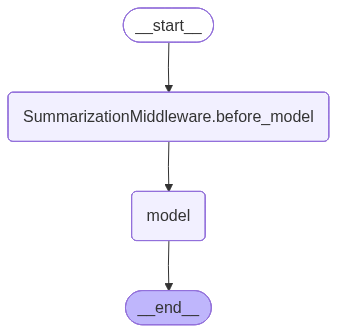

In [2]:
from langchain.agents import create_agent
from langchain.agents.middleware import SummarizationMiddleware
from langgraph.checkpoint.memory import InMemorySaver
from langchain_core.messages import SystemMessage, HumanMessage

# message based communication
agent = create_agent(
    model=custom_llm,
    checkpointer=InMemorySaver(),
    middleware=[
        SummarizationMiddleware(
            model=custom_llm,
            trigger=("messages", 10),
            keep=("messages", 4)
            )
    ],
    tools=[],
    system_prompt="You are a helpful assistant."
)
agent 

In [3]:
### Run with thread id
config = {"configurable": {"thread_id": "test-1"}}

In [4]:
questions = [
    "What is 2+2?",
    "What is 10*5?",
    "What is 100/4?",
    "What is 15-7?",
    "What is 3*3?",
    "Whaat is 4*4?"
    ]

for question in questions:
    response = agent.invoke({"messages": [HumanMessage(content=question)]}, config=config)
    print(f"Question: {question}")
    print(f"Answer: {response}")
    print(f"messages: {len(response['messages'])}")

Question: What is 2+2?
Answer: {'messages': [HumanMessage(content='What is 2+2?', additional_kwargs={}, response_metadata={}, id='81ade9a3-6ebc-4e4b-a746-502443c95576'), AIMessage(content='2 + 2 = 4', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 8, 'prompt_tokens': 32, 'total_tokens': 40, 'completion_tokens_details': None, 'prompt_tokens_details': None}, 'model_provider': 'openai', 'model_name': 'hosted_vllm/gemma-local', 'system_fingerprint': None, 'id': 'chatcmpl-b66c762469d130c2', 'finish_reason': 'stop', 'logprobs': None}, id='lc_run--019f6e15-df45-7471-bb85-e7ae785043b5-0', tool_calls=[], invalid_tool_calls=[], usage_metadata={'input_tokens': 32, 'output_tokens': 8, 'total_tokens': 40, 'input_token_details': {}, 'output_token_details': {}})]}
messages: 2
Question: What is 10*5?
Answer: {'messages': [HumanMessage(content='What is 2+2?', additional_kwargs={}, response_metadata={}, id='81ade9a3-6ebc-4e4b-a746-502443c95576'), AIMessage(c

1. State persistence - The InMemorySaver() checkpointer uses thread_id to store/retrieve conversation history
2. Context continuity - Multiple calls with the same thread_id share the same conversation context
3. Resumability - The agent can continue from where it left off in subsequent calls
This is LangGraph's standard pattern for stateful multi-turn conversations - each unique thread_id represents a separate conversation session.

### token size

In [5]:
from langchain.agents import create_agent
from langchain.agents.middleware import SummarizationMiddleware
from langgraph.checkpoint.memory import InMemorySaver
from langchain_core.messages import SystemMessage, HumanMessage
from langchain_core.tools import tool


@tool
def search_hotels(location: str) -> str:
    """Search hotels - returns long rsponse to use more tokens"""
    return f"""Hotels in {location}:
    1. Hotel A - 5 stars, located in the city center.
    2. Hotel B - 4 stars, located near the beach.
    3. Hotel C - 3 stars, located in the suburbs."""
    
agent = create_agent(
    model=custom_llm,
    checkpointer=InMemorySaver(),
    middleware=[
        SummarizationMiddleware(
            model=custom_llm,
            trigger=("tokens", 100),
            keep=("tokens", 40)
        )
    ],
    tools=[search_hotels],
    system_prompt="You are a helpful assistant."
)
config = {"configurable": {"thread_id": "test-2"}}

def count_tokens(messages):
    total_chars = sum(len(message.content) for message in messages)
    return total_chars//4  # Assuming 1 token is approximately 4 characters

locations = ["Paris","London","Tokyo"]

for location in locations:
    response = agent.invoke({"messages": [HumanMessage(content=f"Search hotels in {location}")]}, config=config)
    tokens = count_tokens(response['messages'])
    print(f"Location: {location}")
    print(f"Answer: {response}")
    print(f"tokens: {tokens}") 

Location: Paris
Answer: {'messages': [HumanMessage(content='Here is a summary of the conversation to date:\n\n## SESSION INTENT\nThe user wants to find and search for hotels in Paris.\n\n## SUMMARY\nThe user has initiated a request to search for hotels in Paris. No specific criteria (budget, dates, or preferences) have been provided yet.\n\n## ARTIFACTS\nNone\n\n## NEXT STEPS\n1. Perform a search for hotels in Paris.\n2. Ask the user for specific preferences (e.g., price range, star rating, neighborhood, or dates) to narrow down the results.', additional_kwargs={'lc_source': 'summarization'}, response_metadata={}, id='ee1c03a6-d915-4463-a4e6-3d9a9444f6e5'), AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 15, 'prompt_tokens': 77, 'total_tokens': 92, 'completion_tokens_details': None, 'prompt_tokens_details': None}, 'model_provider': 'openai', 'model_name': 'hosted_vllm/gemma-local', 'system_fingerprint': None, 'id': 'cha

## Fraction

In [6]:
from langchain.agents import create_agent
from langchain.agents.middleware import SummarizationMiddleware
from langgraph.checkpoint.memory import InMemorySaver
from langchain_core.messages import SystemMessage, HumanMessage
from langchain_core.tools import tool


@tool
def search_hotels(location: str) -> str:
    """Search hotels - returns long rsponse to use more tokens"""
    return f"""Hotels in {location}:
    1. Hotel A - 5 stars, located in the city center.
    2. Hotel B - 4 stars, located near the beach.
    3. Hotel C - 3 stars, located in the suburbs."""
    
agent = create_agent(
    model=custom_llm,
    checkpointer=InMemorySaver(),
    middleware=[
        SummarizationMiddleware(
            model=custom_llm,
            trigger=("fraction", 0.005),
            keep=("fraction", 0.002)
        )
    ],
    tools=[search_hotels],
    system_prompt="You are a helpful assistant."
)
config = {"configurable": {"thread_id": "test-2"}}

def count_tokens(messages):
    total_chars = sum(len(message.content) for message in messages)
    return total_chars//4  # Assuming 1 token is approximately 4 characters

locations = ["Paris","London","Tokyo"]

for location in locations:
    response = agent.invoke({"messages": [HumanMessage(content=f"Search hotels in {location}")]}, config=config)
    tokens = count_tokens(response['messages'])
    fraction = tokens / 4096  # Assuming a max token limit of 4096
    print(f"Location: {location}")
    print(f"Answer: {response}")
    print(f"tokens: {tokens}")
    print(f"fraction: {fraction}") 

ValueError: Model profile information is required to use fractional token limits, and is unavailable for the specified model. Please use absolute token counts instead, or pass `

ChatModel(..., profile={"max_input_tokens": ...})`.

with a desired integer value of the model's maximum input tokens.

### Human in the loop middleware

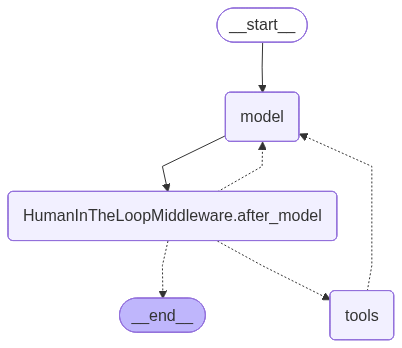

In [23]:
from langchain.agents import create_agent
from langchain.agents.middleware import HumanInTheLoopMiddleware
from langgraph.checkpoint.memory import InMemorySaver
from langchain_core.messages import SystemMessage, HumanMessage


def read_email_tool(email_id: str) -> str:
    """Read email content based on email ID."""
    # For demonstration, returning a mock email content
    return f"Email content for ID {email_id}: This is a sample email content."

def send_email_tool(recipient: str, subject: str, body: str) -> str:
    """Send an email."""
    # For demonstration, returning a mock response
    return f"Email sent to {recipient} with subject '{subject}'."

# message based communication
agent = create_agent(
    model=custom_llm,
    checkpointer=InMemorySaver(),
    middleware=[
        HumanInTheLoopMiddleware(
            interrupt_on={
                "send_email_tool":{
                    "allowed_decisions": ["approve", "edit","reject"]
                },
                "read_email_tool":False,
            }
        )
    ],
    tools=[read_email_tool, send_email_tool],
    system_prompt="You are a helpful assistant."
)
agent 

In [24]:
config = {"configurable": {"thread_id": "test-3"}}
# Step 1: Request to send an email
response = agent.invoke({"messages": [HumanMessage(content=f"Send an email to John with subject Meeting and body Let's meet tomorrow.")]}, config=config)
response

{'messages': [HumanMessage(content="Send an email to John with subject Meeting and body Let's meet tomorrow.", additional_kwargs={}, response_metadata={}, id='986c6fb7-ee98-4e2d-b6ee-eb0f6c3354f9'),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 34, 'prompt_tokens': 159, 'total_tokens': 193, 'completion_tokens_details': None, 'prompt_tokens_details': None}, 'model_provider': 'openai', 'model_name': 'hosted_vllm/gemma-local', 'system_fingerprint': None, 'id': 'chatcmpl-868e4c211f2f1545', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--019f6e20-18ba-7313-8037-e7c84c7f18aa-0', tool_calls=[{'name': 'send_email_tool', 'args': {'body': "Let's meet tomorrow.", 'recipient': 'John', 'subject': 'Meeting'}, 'id': 'chatcmpl-tool-9553aa879470f7ab', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 159, 'output_tokens': 34, 'total_tokens': 193, 'input_token_details': {}, 'output_token_deta

In [25]:
# step 2: Approve the email sending

from langgraph.types import Command


if "__interrupt__" in response:
    print("Email sending is waiting for human approval.")
    
    result = agent.invoke(
        Command(
            resume={
                "decisions": [
                    {"type":"approve"}
                ]
            }
        ),
        config=config
    )
    
    print("Response after approval:", result)
    print(f"Messages: {result['messages'][-1].content}")

Email sending is waiting for human approval.
Response after approval: {'messages': [HumanMessage(content="Send an email to John with subject Meeting and body Let's meet tomorrow.", additional_kwargs={}, response_metadata={}, id='986c6fb7-ee98-4e2d-b6ee-eb0f6c3354f9'), AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 34, 'prompt_tokens': 159, 'total_tokens': 193, 'completion_tokens_details': None, 'prompt_tokens_details': None}, 'model_provider': 'openai', 'model_name': 'hosted_vllm/gemma-local', 'system_fingerprint': None, 'id': 'chatcmpl-868e4c211f2f1545', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--019f6e20-18ba-7313-8037-e7c84c7f18aa-0', tool_calls=[{'name': 'send_email_tool', 'args': {'body': "Let's meet tomorrow.", 'recipient': 'John', 'subject': 'Meeting'}, 'id': 'chatcmpl-tool-9553aa879470f7ab', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 159, 'output_tokens': 34

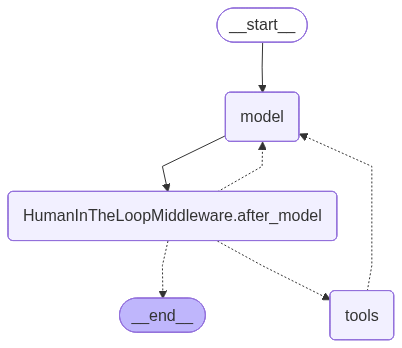

In [26]:
from langchain.agents import create_agent
from langchain.agents.middleware import HumanInTheLoopMiddleware
from langgraph.checkpoint.memory import InMemorySaver
from langchain_core.messages import SystemMessage, HumanMessage


def read_email_tool(email_id: str) -> str:
    """Read email content based on email ID."""
    # For demonstration, returning a mock email content
    return f"Email content for ID {email_id}: This is a sample email content."

def send_email_tool(recipient: str, subject: str, body: str) -> str:
    """Send an email."""
    # For demonstration, returning a mock response
    return f"Email sent to {recipient} with subject '{subject}'."

# message based communication
agent = create_agent(
    model=custom_llm,
    checkpointer=InMemorySaver(),
    middleware=[
        HumanInTheLoopMiddleware(
            interrupt_on={
                "send_email_tool":{
                    "allowed_decisions": ["approve", "edit","reject"]
                },
                "read_email_tool":False,
            }
        )
    ],
    tools=[read_email_tool, send_email_tool],
    system_prompt="You are a helpful assistant."
)
agent 

In [27]:
config = {"configurable": {"thread_id": "test-3"}}
# Step 1: Request to send an email
response = agent.invoke({"messages": [HumanMessage(content=f"Send an email to John with subject Meeting and body Let's meet tomorrow.")]}, config=config)
response

{'messages': [HumanMessage(content="Send an email to John with subject Meeting and body Let's meet tomorrow.", additional_kwargs={}, response_metadata={}, id='76c67b66-41b8-4302-8f6b-3a9658884462'),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 34, 'prompt_tokens': 159, 'total_tokens': 193, 'completion_tokens_details': None, 'prompt_tokens_details': None}, 'model_provider': 'openai', 'model_name': 'hosted_vllm/gemma-local', 'system_fingerprint': None, 'id': 'chatcmpl-974f06b0cfa15ae9', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--019f6e20-3cba-7561-bff9-4322af5b841f-0', tool_calls=[{'name': 'send_email_tool', 'args': {'body': "Let's meet tomorrow.", 'recipient': 'John', 'subject': 'Meeting'}, 'id': 'chatcmpl-tool-b109ba47cc42c8c8', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 159, 'output_tokens': 34, 'total_tokens': 193, 'input_token_details': {}, 'output_token_deta

In [28]:
# step 2: Approve the email sending

from langgraph.types import Command


if "__interrupt__" in response:
    print("Email sending is waiting for human approval.")
    
    result = agent.invoke(
        Command(
            resume={
                "decisions": [
                    {"type":"reject"}
                ]
            }
        ),
        config=config
    )
    
    print("Response after approval:", result)
    print(f"Messages: {result['messages'][-1].content}")

Email sending is waiting for human approval.
Response after approval: {'messages': [HumanMessage(content="Send an email to John with subject Meeting and body Let's meet tomorrow.", additional_kwargs={}, response_metadata={}, id='76c67b66-41b8-4302-8f6b-3a9658884462'), AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 34, 'prompt_tokens': 159, 'total_tokens': 193, 'completion_tokens_details': None, 'prompt_tokens_details': None}, 'model_provider': 'openai', 'model_name': 'hosted_vllm/gemma-local', 'system_fingerprint': None, 'id': 'chatcmpl-974f06b0cfa15ae9', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--019f6e20-3cba-7561-bff9-4322af5b841f-0', tool_calls=[{'name': 'send_email_tool', 'args': {'body': "Let's meet tomorrow.", 'recipient': 'John', 'subject': 'Meeting'}, 'id': 'chatcmpl-tool-b109ba47cc42c8c8', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 159, 'output_tokens': 34

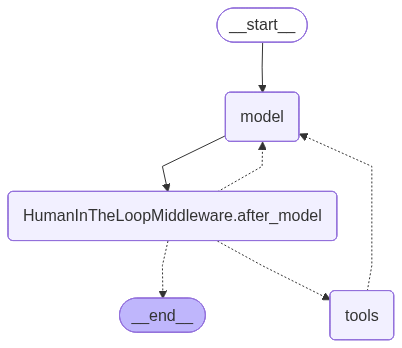

In [29]:
from langchain.agents import create_agent
from langchain.agents.middleware import HumanInTheLoopMiddleware
from langgraph.checkpoint.memory import InMemorySaver
from langchain_core.messages import SystemMessage, HumanMessage


def read_email_tool(email_id: str) -> str:
    """Read email content based on email ID."""
    # For demonstration, returning a mock email content
    return f"Email content for ID {email_id}: This is a sample email content."

def send_email_tool(recipient: str, subject: str, body: str) -> str:
    """Send an email."""
    # For demonstration, returning a mock response
    return f"Email sent to {recipient} with subject '{subject}'."

# message based communication
agent = create_agent(
    model=custom_llm,
    checkpointer=InMemorySaver(),
    middleware=[
        HumanInTheLoopMiddleware(
            interrupt_on={
                "send_email_tool":{
                    "allowed_decisions": ["approve", "edit","reject"]
                },
                "read_email_tool":False,
            }
        )
    ],
    tools=[read_email_tool, send_email_tool],
    system_prompt="You are a helpful assistant."
)
agent 

In [30]:
config = {"configurable": {"thread_id": "test-7"}}
# Step 1: Request to send an email
response = agent.invoke({"messages": [HumanMessage(content=f"Send an email to John with subject Meeting and body Let's meet tomorrow.")]}, config=config)
response

{'messages': [HumanMessage(content="Send an email to John with subject Meeting and body Let's meet tomorrow.", additional_kwargs={}, response_metadata={}, id='6953df87-5d90-4057-8362-7925c9c58813'),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 34, 'prompt_tokens': 159, 'total_tokens': 193, 'completion_tokens_details': None, 'prompt_tokens_details': None}, 'model_provider': 'openai', 'model_name': 'hosted_vllm/gemma-local', 'system_fingerprint': None, 'id': 'chatcmpl-89cac3a2cfac4c84', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--019f6e20-5317-7593-a99c-d7e50b3a25a3-0', tool_calls=[{'name': 'send_email_tool', 'args': {'body': "Let's meet tomorrow.", 'recipient': 'John', 'subject': 'Meeting'}, 'id': 'chatcmpl-tool-86fd47207821a164', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 159, 'output_tokens': 34, 'total_tokens': 193, 'input_token_details': {}, 'output_token_deta

In [31]:
# Step 2: Edit and approve
if "__interrupt__" in result:
    print("⏸ Paused! Editing...")

    result = agent.invoke(
        Command(
            resume={
                "decisions": [
                    {
                        "type": "edit",
                        "edited_action": {
                            "name": "send_email_tool",        # Tool name
                            "args": {                         # New arguments
                                "recipient": "correct@email.com",
                                "subject": "Corrected Subject",
                                "body": "This was edited by human before sending"
                            }
                        }
                    }
                ]
            }
        ),
        config=config
    )


In [32]:
result

{'messages': [HumanMessage(content="Send an email to John with subject Meeting and body Let's meet tomorrow.", additional_kwargs={}, response_metadata={}, id='76c67b66-41b8-4302-8f6b-3a9658884462'),
  AIMessage(content='', additional_kwargs={'refusal': None}, response_metadata={'token_usage': {'completion_tokens': 34, 'prompt_tokens': 159, 'total_tokens': 193, 'completion_tokens_details': None, 'prompt_tokens_details': None}, 'model_provider': 'openai', 'model_name': 'hosted_vllm/gemma-local', 'system_fingerprint': None, 'id': 'chatcmpl-974f06b0cfa15ae9', 'finish_reason': 'tool_calls', 'logprobs': None}, id='lc_run--019f6e20-3cba-7561-bff9-4322af5b841f-0', tool_calls=[{'name': 'send_email_tool', 'args': {'body': "Let's meet tomorrow.", 'recipient': 'John', 'subject': 'Meeting'}, 'id': 'chatcmpl-tool-b109ba47cc42c8c8', 'type': 'tool_call'}], invalid_tool_calls=[], usage_metadata={'input_tokens': 159, 'output_tokens': 34, 'total_tokens': 193, 'input_token_details': {}, 'output_token_deta